In [1]:
import os
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)

SEED = 42
np.random.seed(SEED)

if not os.path.exists("datasets"):
    os.mkdir("datasets")

In [5]:
DATA_DIR = "datasets"
BOOK_GLOB_HINT = "df_book_10"

def _find_real_parquet(data_dir=DATA_DIR, hint=BOOK_GLOB_HINT):
    if not os.path.isdir(data_dir):
        return None
    candidates = [f for f in os.listdir(data_dir) if hint in f and f.endswith(".parquet")]
    return os.path.join(data_dir, candidates[0]) if candidates else None



df_lob = pl.scan_parquet(_find_real_parquet()).collect().to_pandas()

df_lob.head(5)


,timestamp,local_timestamp,bids[0].price,bids[0].amount,asks[0].price,asks[0].amount,bids[1].price,bids[1].amount,asks[1].price,asks[1].amount,...,asks[7].price,asks[7].amount,bids[8].price,bids[8].amount,asks[8].price,asks[8].amount,bids[9].price,bids[9].amount,asks[9].price,asks[9].amount
0,1775001600571000,1775001601136017,68235.3,2.908,68235.4,6.377,68235.2,0.014,68235.5,0.020,...,68236.5,0.002,68234.3,0.014,68236.6,0.002,68234.2,0.002,68236.8,0.003
1,1775001601141000,1775001601143545,68235.3,1.180,68235.4,6.377,68235.2,0.014,68235.5,0.020,...,68236.5,0.002,68234.3,0.014,68236.6,0.002,68234.2,0.002,68236.8,0.003
2,1775001601193000,1775001601194988,68235.3,0.317,68235.4,7.100,68235.2,0.014,68235.5,0.020,...,68236.5,0.002,68234.3,0.014,68236.6,0.002,68234.2,0.002,68236.8,0.003
3,1775001601245000,1775001601247772,68235.3,0.133,68235.4,7.106,68235.2,0.014,68235.5,0.020,...,68236.5,0.002,68234.3,0.014,68236.6,0.002,68234.2,0.002,68236.8,0.003
4,1775001601297000,1775001601299697,68234.4,3.047,68234.5,13.275,68234.3,0.012,68234.6,0.004,...,68235.8,0.152,68233.4,0.009,68235.9,0.045,68233.3,0.004,68236.4,0.001


In [11]:
print(type(df_lob))

<class 'pandas.core.frame.DataFrame'>


In [14]:
print("Número de filas:", df_lob.shape[0])
print("Número de columnas:", df_lob.shape[1])
print()
print("Esquema de columnas y tipos:")
print(df_lob.shape)


Número de filas: 1393824
Número de columnas: 42

Esquema de columnas y tipos:
(1393824, 42)


In [20]:
# 1. Contar nulos por columna y calcular el porcentaje
nulls_series = df_lob.isnull().sum()
pct_series = 100 * nulls_series / len(df_lob)

# 2. Construir el DataFrame de resumen
nulls_pd = pd.DataFrame({"n_nulos": nulls_series, "pct_nulos": pct_series})

# 3. Mostrar resultados si existen nulos
print("Columnas con algún valor nulo:")
display(nulls_pd[nulls_pd["n_nulos"] > 0])

# 4. Mensaje de control
if nulls_pd["n_nulos"].sum() == 0:
    print("No se han detectado valores nulos en el snapshot crudo del libro.")


Columnas con algún valor nulo:


,n_nulos,pct_nulos


No se han detectado valores nulos en el snapshot crudo del libro.


In [18]:
resumen_l1 = df_lob[
    ["bids[0].price", "bids[0].amount", "asks[0].price", "asks[0].amount"]
].describe()

# Mostrar el resultado
resumen_l1

,bids[0].price,bids[0].amount,asks[0].price,asks[0].amount
count,1.393824e+06,1.393824e+06,1.393824e+06,1.393824e+06
mean,6.835760e+04,5.386482e+00,6.835770e+04,5.435070e+00
std,3.262738e+02,5.196182e+00,3.262744e+02,5.609248e+00
min,6.753840e+04,1.000000e-03,6.753850e+04,1.000000e-03
25%,6.811010e+04,2.064000e+00,6.811020e+04,1.957000e+00
50%,6.834400e+04,4.036000e+00,6.834410e+04,4.026000e+00
75%,6.857320e+04,7.646000e+00,6.857330e+04,7.735000e+00
max,6.928790e+04,3.052640e+02,6.928800e+04,2.107120e+02


In [24]:
ts = df_lob["timestamp"].to_numpy()
diffs_us = np.diff(ts)               # diferencias en microsegundos (formato nativo de tardis-dev)
diffs_ms = diffs_us / 1000.0

print(f"Nº de intervalos analizados: {len(diffs_ms):,}")
print(f"Intervalo medio entre snapshots: {diffs_ms.mean():.2f} ms")
print(f"Mediana del intervalo:            {np.median(diffs_ms):.2f} ms")
print(f"Desviación estándar:               {diffs_ms.std():.2f} ms")
print(f"Percentil 99:                      {np.percentile(diffs_ms, 99):.2f} ms")
print(f"Intervalo máximo detectado:        {diffs_ms.max():.2f} ms  (posible hueco / gap)")

horizon_k100_s = 100 * np.median(diffs_ms) / 1000
print(f"\n➡️  Con esta cadencia mediana, el horizonte k=100 equivale aprox. a {horizon_k100_s:.2f} segundos de anticipación.")
print(np.unique(diffs_ms))

Nº de intervalos analizados: 1,393,823
Intervalo medio entre snapshots: 61.99 ms
Mediana del intervalo:            52.00 ms
Desviación estándar:               32.71 ms
Percentil 99:                      208.00 ms
Intervalo máximo detectado:        2721.00 ms  (posible hueco / gap)

➡️  Con esta cadencia mediana, el horizonte k=100 equivale aprox. a 5.20 segundos de anticipación.
[  51.   52.   54.   56.   57.   58.  102.  104.  106.  108.  146.  154.
  156.  158.  160.  162.  174.  188.  208.  210.  212.  214.  216.  218.
  260.  262.  264.  295.  312.  314.  316.  317.  344.  347.  364.  366.
  368.  380.  416.  418.  420.  468.  470.  514.  520.  522.  524.  526.
  570.  572.  623.  624.  626.  641.  671.  676.  678.  726.  728.  764.
  768.  780.  832.  833.  884.  936.  988. 1040. 2058. 2721.]


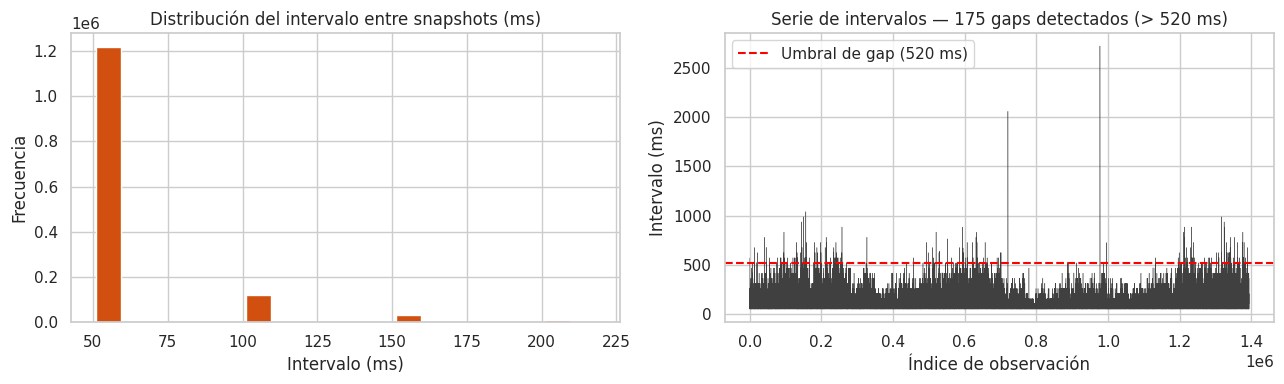

Número de huecos (gaps) > 520 ms: 175 (0.013% de los intervalos)


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(diffs_ms[diffs_ms < np.percentile(diffs_ms, 99.5)], bins=20, color="#D2500F")
axes[0].set_title("Distribución del intervalo entre snapshots (ms)")
axes[0].set_xlabel("Intervalo (ms)")
axes[0].set_ylabel("Frecuencia")

# Huecos relevantes: intervalos muy superiores a la mediana (posibles cortes de conexión / baja actividad)
gap_threshold = np.median(diffs_ms) * 10
gaps_idx = np.where(diffs_ms > gap_threshold)[0]
axes[1].plot(diffs_ms, lw=0.3, color="#404040")
axes[1].axhline(gap_threshold, color="red", linestyle="--", label=f"Umbral de gap ({gap_threshold:.0f} ms)")
axes[1].set_title(f"Serie de intervalos — {len(gaps_idx)} gaps detectados (> {gap_threshold:.0f} ms)")
axes[1].set_xlabel("Índice de observación")
axes[1].set_ylabel("Intervalo (ms)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Número de huecos (gaps) > {gap_threshold:.0f} ms: {len(gaps_idx)} "
      f"({100 * len(gaps_idx) / len(diffs_ms):.3f}% de los intervalos)")

/tmp/ipykernel_1072/4242067028.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["datetime"] = pd.to_datetime(df_plot["timestamp"], unit="us")
/tmp/ipykernel_1072/4242067028.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["mid_price"]=(df_plot["bids[0].price"]+df_plot["asks[0].price"])/2


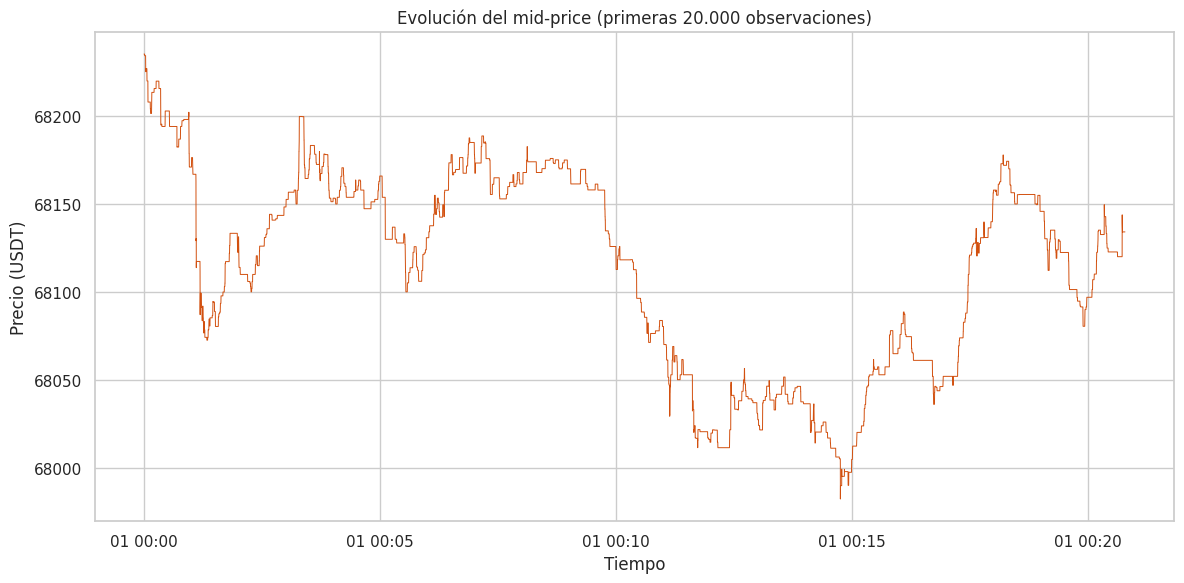

In [32]:

df_plot = df_lob.head(20000)
df_plot["datetime"] = pd.to_datetime(df_plot["timestamp"], unit="us")
df_plot["mid_price"]=(df_plot["bids[0].price"]+df_plot["asks[0].price"])/2
fig, axes = plt.subplots(1, 1, figsize=(12, 6), sharex=True)

axes.plot(df_plot["datetime"], df_plot["mid_price"], color="#D2500F", lw=0.7)
axes.set_title("Evolución del mid-price (primeras 20.000 observaciones)")
axes.set_ylabel("Precio (USDT)")
axes.set_xlabel("Tiempo")




plt.tight_layout()
plt.show()


## 7. Sensibilidad del etiquetado a la elección de α


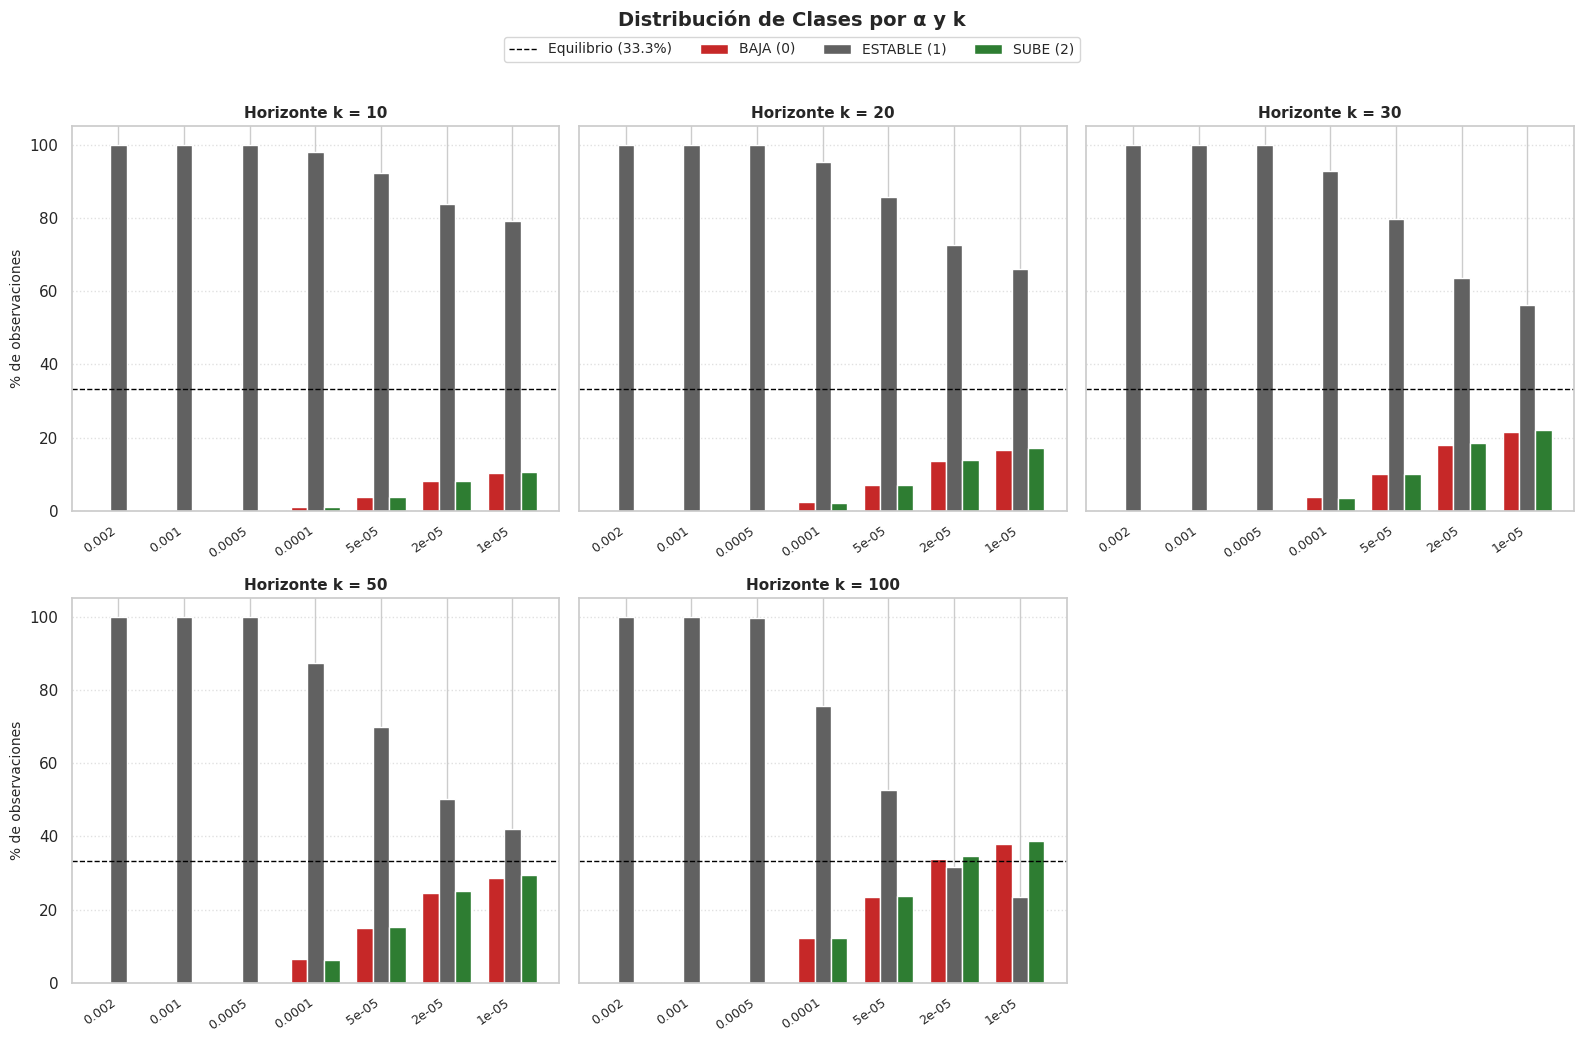

Proceso finalizado y gráfico guardado en 'sensibilidad_clases.png'.


In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

df_lob["mid_price"]=(df_lob['bids[0].price']+df_lob['asks[0].price'])/2

def compute_labels(df: pl.DataFrame, alpha: float, k: int) -> pl.DataFrame:
    # 1. Media móvil futura EXACTA en el rango [t+1, t+k]
    future_mid_avg = (
        pl.col("mid_price")
        .reverse()
        .rolling_mean(window_size=k, min_samples=k)
        .reverse()
        .shift(-1)
    )

    pct_change = (future_mid_avg - pl.col("mid_price")) / pl.col("mid_price")

    # 2. Generar etiquetas discretas (0: BAJA, 1: ESTABLE, 2: SUBE)
    df_ = df.with_columns(
        pl.when(pct_change >= alpha)
        .then(2)
        .when(pct_change <= -alpha)
        .then(0)
        .otherwise(1)
        .alias("label")
    )

    return df_.drop_nulls(subset=["label"])


# Definición de parámetros
alphas_candidatas = [0.002, 0.001, 0.0005, 0.0001, 0.00005, 0.00002, 0.00001]
ks_candidatos = [10, 20, 30, 50, 100]

resultados = []

# Iterar sobre las combinaciones de k y alpha
for k in ks_candidatos:
    for a in alphas_candidatas:
        df_lab = compute_labels(pl.from_pandas(df_lob), alpha=a, k=k)

        # Contar ocurrencias por etiqueta
        counts = df_lab["label"].value_counts()
        counts_dict = dict(
            zip(counts["label"].to_list(), counts["count"].to_list())
        )
        total = sum(counts_dict.values())

        if total > 0:
            resultados.append({
                "k": k,
                "alpha": a,
                "pct_BAJA": 100 * counts_dict.get(0, 0) / total,
                "pct_ESTABLE": 100 * counts_dict.get(1, 0) / total,
                "pct_SUBE": 100 * counts_dict.get(2, 0) / total,
                "total_muestras": total,
            })

# DataFrame final con los resultados agregados
df_sensibilidad = pd.DataFrame(resultados)


# ==============================================================================
# BLOQUE DE GRAFICACIÓN E HISTOGRAMA / BARRAS
# ==============================================================================
ks_unicos = sorted(df_sensibilidad["k"].unique())
n_ks = len(ks_unicos)

ncols = 3
nrows = (n_ks + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows), sharey=True
)
axes = axes.flatten()

width = 0.25

for i, k_val in enumerate(ks_unicos):
    ax = axes[i]
    df_k = df_sensibilidad[df_sensibilidad["k"] == k_val].reset_index(
        drop=True
    )
    x = np.arange(len(df_k))

    # Barras por cada etiqueta
    ax.bar(
        x - width,
        df_k["pct_BAJA"],
        width=width,
        label="BAJA (0)",
        color="#C62828",
    )
    ax.bar(
        x,
        df_k["pct_ESTABLE"],
        width=width,
        label="ESTABLE (1)",
        color="#616161",
    )
    ax.bar(
        x + width,
        df_k["pct_SUBE"],
        width=width,
        label="SUBE (2)",
        color="#2E7D32",
    )

    # Línea de equilibrio 33.3%
    ax.axhline(
        33.33,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Equilibrio (33.3%)" if i == 0 else "",
    )

    # Etiquetas del eje X (notación científica para alfas pequeñas)
    ax.set_xticks(x)
    labels_alpha = [
        f"{a:.0e}" if a < 0.0001 else f"{a}" for a in df_k["alpha"]
    ]
    ax.set_xticklabels(labels_alpha, rotation=35, ha="right", fontsize=9)
    ax.set_title(f"Horizonte k = {k_val}", fontsize=11, fontweight="bold")
    ax.grid(axis="y", linestyle=":", alpha=0.6)

    if i % ncols == 0:
        ax.set_ylabel("% de observaciones", fontsize=10)

# Ocultar paneles sobrantes si el total no es múltiplo de 3
for i in range(n_ks, len(axes)):
    fig.delaxes(axes[i])

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=4,
    frameon=True,
    fontsize=10,
)

plt.suptitle(
    "Distribución de Clases por α y k", y=1.04, fontsize=14, fontweight="bold"
)
plt.tight_layout()

# Guardar figura en PNG
plt.savefig("sensibilidad_clases.png", bbox_inches="tight", dpi=300)
plt.show()

print("Proceso finalizado y gráfico guardado en 'sensibilidad_clases.png'.")

**Hipotesisi nula**


In [ ]:
FEATURES_PARQUET_PATH = "dataset_completo (2).parquet"  # ajusta si guardaste con otro nombre
HORIZONS = [10, 20, 30, 50, 100]

if "dataset_final" in globals():
    df_feat = dataset_final.collect().head(50000) if isinstance(dataset_final, pl.LazyFrame) else dataset_final
else:
    df_feat = pl.read_parquet(FEATURES_PARQUET_PATH).limit(50000)

df_feat = df_feat.to_pandas()
print(f"Filas: {len(df_feat):,} | Columnas: {df_feat.shape[1]}")

GROUP_A_COLS = ["v1", "v2", "v3", "v4", "mid_price_coordenada"]
all_v_cols = [f"v{i}" for i in range(1, 145) if f"v{i}" in df_feat.columns ]
GROUP_B_EXTRA_COLS = [c for c in all_v_cols if c not in GROUP_A_COLS]
if "OBI_Nivel_1" in df_feat.columns:
    GROUP_B_EXTRA_COLS.append("OBI_Nivel_1")

label_cols_available = [f"label_k_{k}" for k in HORIZONS if f"label_k_{k}" in df_feat.columns]
print("Horizontes disponibles:", label_cols_available)


if "timestamp" in df_feat.columns:
    dt_ms_median = pd.Series(df_feat["timestamp"]).diff().median() / 1000.0
    print(f"\nDelta-t mediano entre ticks: {dt_ms_median:.3f} ms")
    for k in HORIZONS:
        print(f"  k={k:>3} ticks =~ {k * dt_ms_median:.1f} ms")


Filas: 50,000 | Columnas: 150
Horizontes disponibles: ['label_k_10', 'label_k_20', 'label_k_30', 'label_k_50', 'label_k_100']


In [54]:

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def walk_forward_split(d, train_frac=0.7):
    n = len(d)
    cut = int(n * train_frac)
    return d.iloc[:cut], d.iloc[cut:]

def paired_permutation_test(y_true, pred_ref, pred_new, n_perm=300, seed=42):
    """p-valor de que pred_new mejora a pred_ref en F1-macro (test de permutacion pareado)."""
    rng = np.random.default_rng(seed)
    f1_ref = f1_score(y_true, pred_ref, average="macro")
    f1_new = f1_score(y_true, pred_new, average="macro")
    diff_obs = f1_new - f1_ref
    n = len(y_true)
    null_diffs = np.empty(n_perm)
    for i in range(n_perm):
        swap = rng.random(n) < 0.5
        p1 = np.where(swap, pred_ref, pred_new)
        p2 = np.where(swap, pred_new, pred_ref)
        null_diffs[i] = f1_score(y_true, p2, average="macro") - f1_score(y_true, p1, average="macro")
    p_value = (np.sum(null_diffs >= diff_obs) + 1) / (n_perm + 1)
    return f1_ref, f1_new, diff_obs, p_value

resultados_h1 = []

for k in HORIZONS:
    label_col = f"label_k_{k}"
    if label_col not in df_feat.columns:
        continue

    needed_cols = GROUP_A_COLS + GROUP_B_EXTRA_COLS + [label_col]
    df_model = df_feat[needed_cols].dropna().reset_index(drop=True)

    train_df, test_df = walk_forward_split(df_model)

    X_train_A = train_df[GROUP_A_COLS].to_numpy()
    X_test_A  = test_df[GROUP_A_COLS].to_numpy()
    X_train_B = train_df[GROUP_A_COLS + GROUP_B_EXTRA_COLS].to_numpy()
    X_test_B  = test_df[GROUP_A_COLS + GROUP_B_EXTRA_COLS].to_numpy()
    y_train = train_df[label_col].to_numpy()
    y_test  = test_df[label_col].to_numpy()

    # --- RW puro: Dummy classifier (no ve ninguna variable del libro) ---
    clf_rw = DummyClassifier(strategy="stratified", random_state=42)
    clf_rw.fit(X_train_A, y_train)  # las X no importan, solo usa y_train
    pred_rw = clf_rw.predict(X_test_A)

    # --- Grupo A: solo variables tradicionales de Nivel 1 ---
    scaler_A = StandardScaler().fit(X_train_A)
    clf_A = LogisticRegression(max_iter=300, multi_class="multinomial", class_weight="balanced")
    clf_A.fit(scaler_A.transform(X_train_A), y_train)
    pred_A = clf_A.predict(scaler_A.transform(X_test_A))

    # --- Grupo B: L2 profunda completa (FI-2010 + OBI) ---
    scaler_B = StandardScaler().fit(X_train_B)
    clf_B = LogisticRegression(max_iter=300, multi_class="multinomial", class_weight="balanced")
    clf_B.fit(scaler_B.transform(X_train_B), y_train)
    pred_B = clf_B.predict(scaler_B.transform(X_test_B))

    f1_rw = f1_score(y_test, pred_rw, average="macro")
    _, f1_A, diff_A_vs_rw, p_A_vs_rw = paired_permutation_test(y_test, pred_rw, pred_A)
    _, f1_B, diff_B_vs_A, p_B_vs_A   = paired_permutation_test(y_test, pred_A, pred_B)
    _, _,    diff_B_vs_rw, p_B_vs_rw = paired_permutation_test(y_test, pred_rw, pred_B)

    resultados_h1.append({
        "k (ticks)": k,
        "F1 RW puro (Dummy)": f1_rw,
        "F1 Grupo A (tradicional)": f1_A,
        "F1 Grupo B (L2 profunda)": f1_B,
        "Delta A vs RW": diff_A_vs_rw,
        "p (A vs RW)": p_A_vs_rw,
        "Delta B vs A": diff_B_vs_A,
        "p (B vs A)": p_B_vs_A,
        "Delta B vs RW": diff_B_vs_rw,
        "p (B vs RW)": p_B_vs_rw,
    })

    print(f"k={k:>4} | F1 RW={f1_rw:.4f}  F1 A={f1_A:.4f} (p vs RW={p_A_vs_rw:.4f})  "
          f"F1 B={f1_B:.4f} (p vs A={p_B_vs_A:.4f}, p vs RW={p_B_vs_rw:.4f})")

h1_multihorizonte = pd.DataFrame(resultados_h1).set_index("k (ticks)")
h1_multihorizonte


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/mo

k=  10 | F1 RW=0.3388  F1 A=0.0681 (p vs RW=1.0000)  F1 B=0.3128 (p vs A=0.0033, p vs RW=1.0000)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/mo

k=  20 | F1 RW=0.3382  F1 A=0.0780 (p vs RW=1.0000)  F1 B=0.3191 (p vs A=0.0033, p vs RW=1.0000)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/mo

...

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/mo

k=  50 | F1 RW=0.3309  F1 A=0.0972 (p vs RW=1.0000)  F1 B=0.3431 (p vs A=0.0033, p vs RW=0.0498)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/mo

k= 100 | F1 RW=0.3341  F1 A=0.1162 (p vs RW=1.0000)  F1 B=0.4057 (p vs A=0.0033, p vs RW=0.0033)


,F1 RW puro (Dummy),F1 Grupo A (tradicional),F1 Grupo B (L2 profunda),Delta A vs RW,p (A vs RW),Delta B vs A,p (B vs A),Delta B vs RW,p (B vs RW)
k (ticks),,,,,,,,,
10,0.338779,0.068093,0.312764,-0.270686,1.0,0.244670,0.003322,-0.026016,1.000000
20,0.338234,0.078048,0.319075,-0.260186,1.0,0.241027,0.003322,-0.019159,1.000000
30,0.328897,0.084802,0.332785,-0.244095,1.0,0.247984,0.003322,0.003888,0.259136
50,0.330874,0.097238,0.343090,-0.233635,1.0,0.245852,0.003322,0.012216,0.049834
100,0.334055,0.116237,0.405713,-0.217818,1.0,0.289476,0.003322,0.071658,0.003322


**correlation**

In [58]:
df=df_feat
df=df.drop(['mid_price_coordenada','label_k_10','label_k_20','label_k_30','label_k_50'],axis=1)

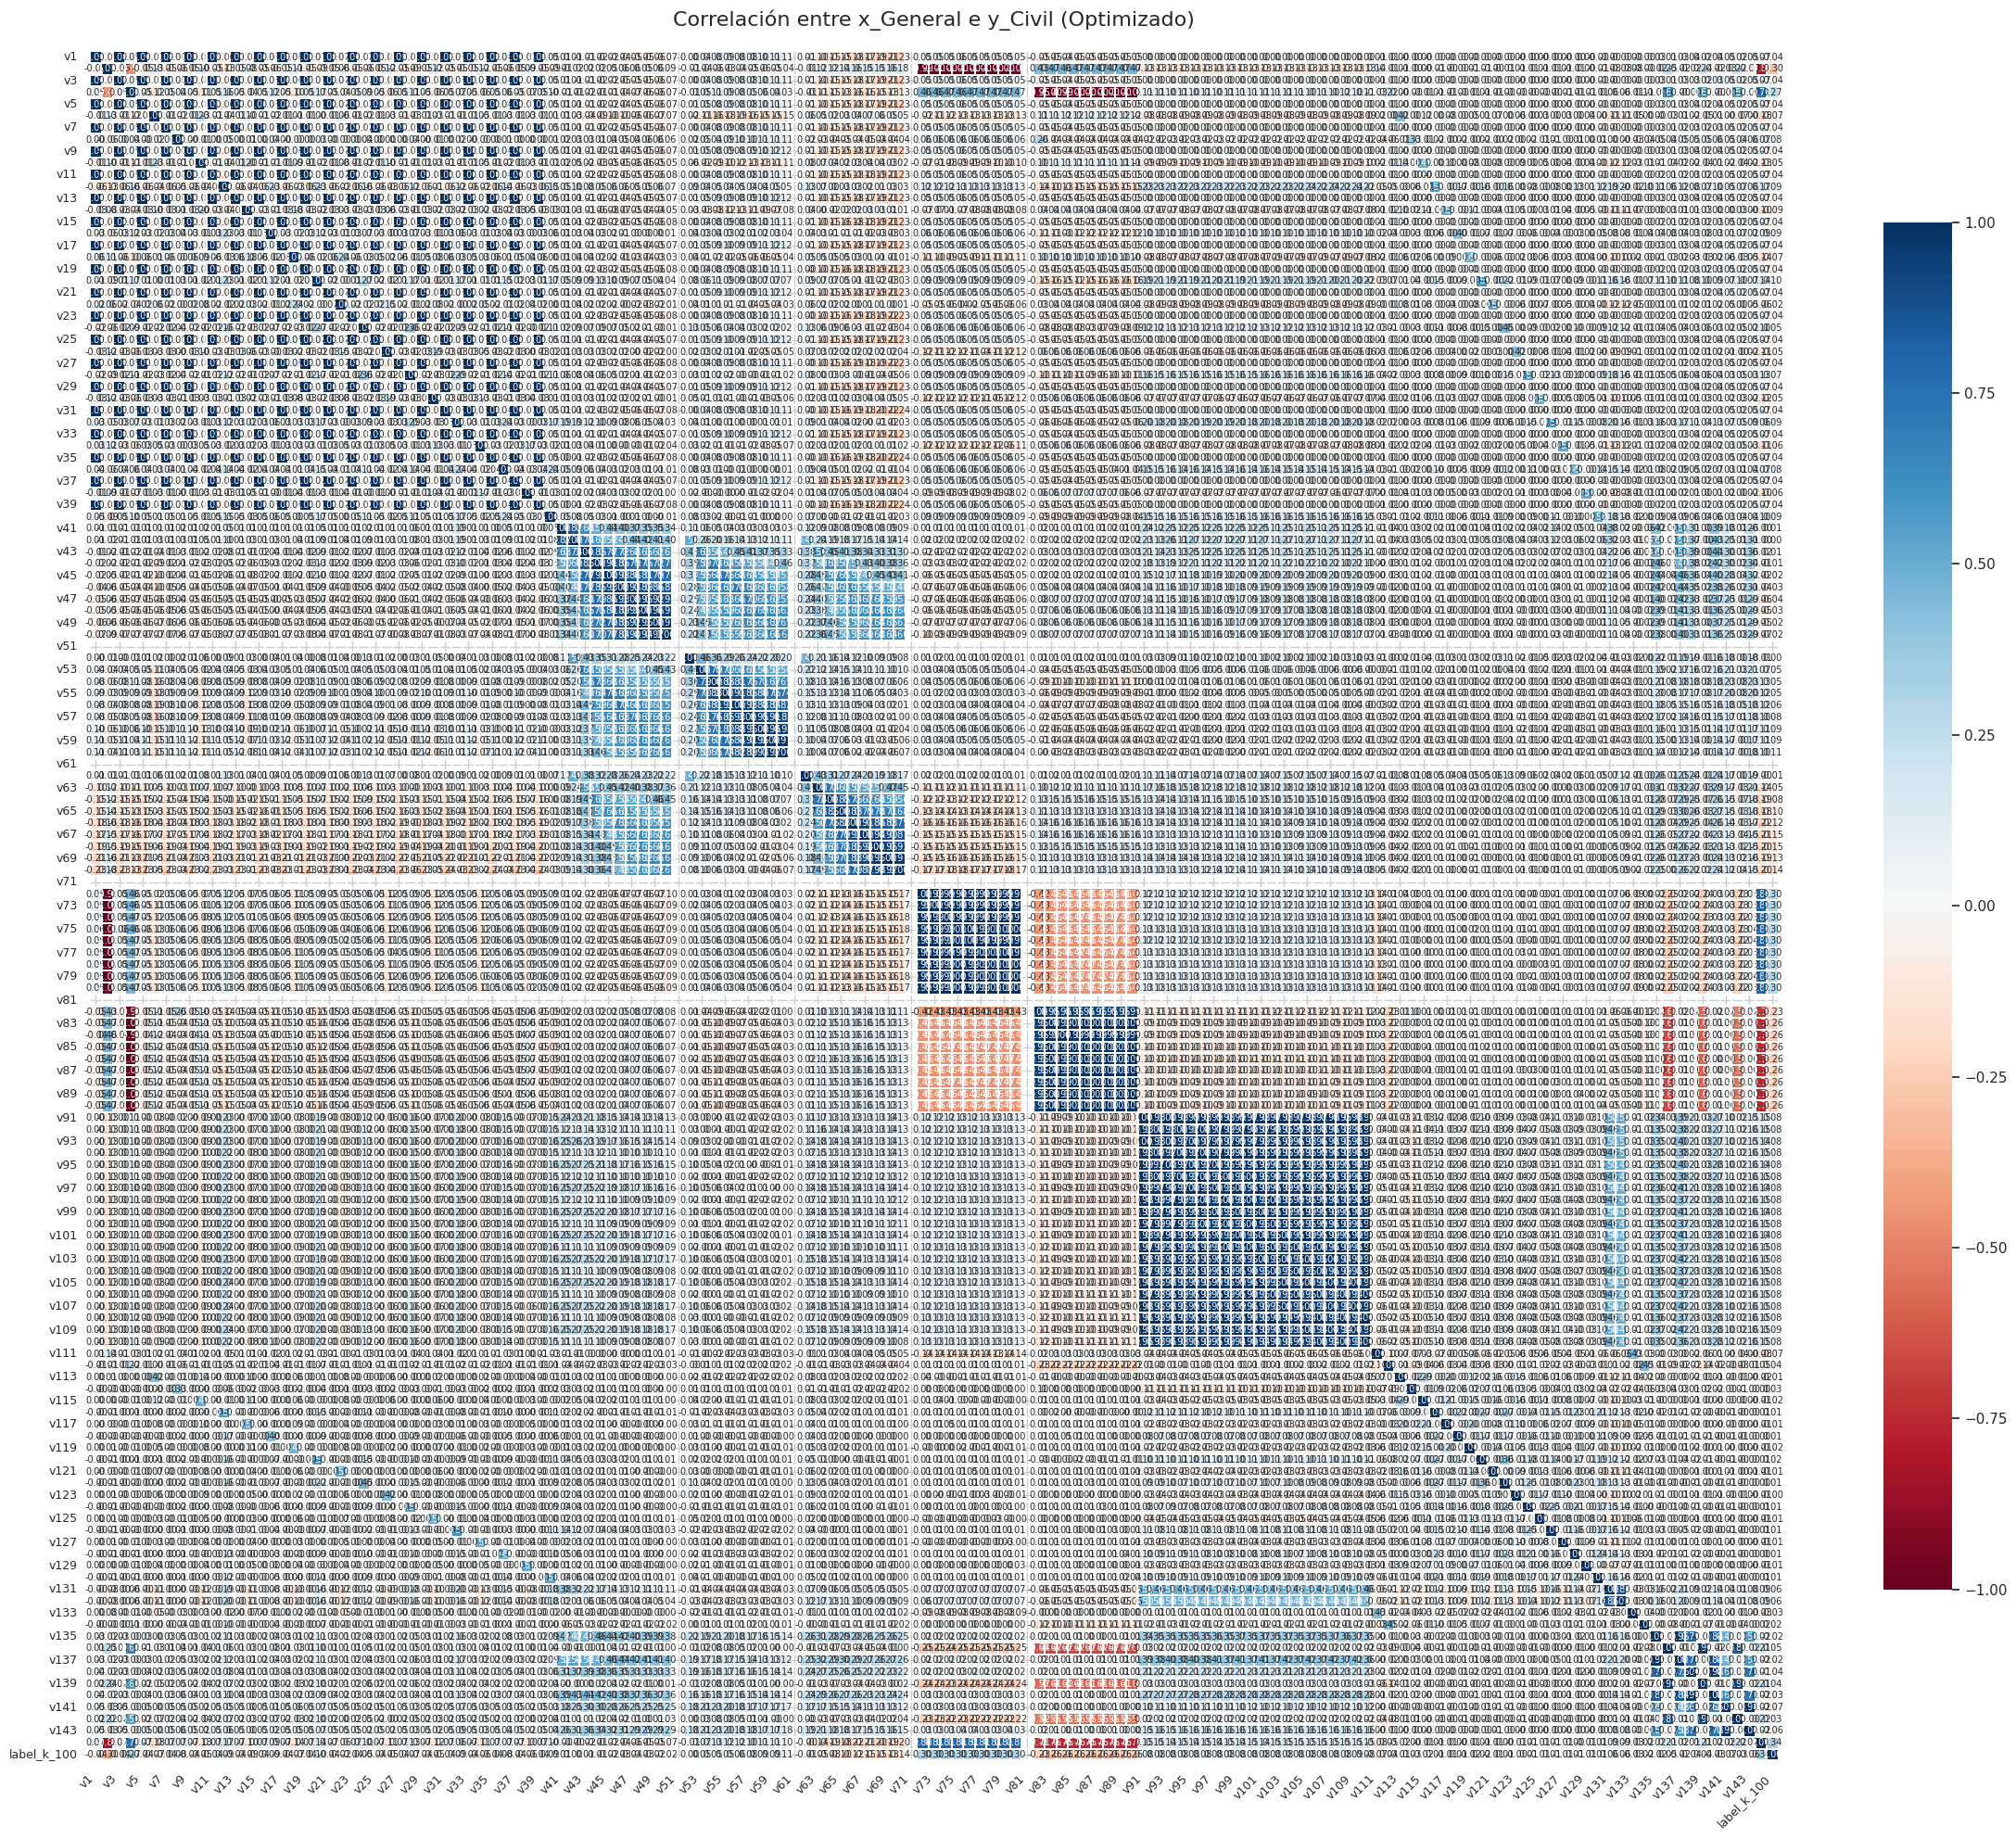

<Figure size 1100x400 with 0 Axes>

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(24, 20))


sns.heatmap(
    df.corr(),
    annot=True,             
    fmt=".2f",
    cmap="RdBu",            
    vmin=-1, vmax=1,        
    linewidths=0.1,         
    annot_kws={"size": 7},  
    cbar_kws={"shrink": 0.8}
)

plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.title('Correlación entre x_General e y (Optimizado)', fontsize=16, pad=20)
plt.tight_layout() 
plt.show()
plt.savefig('matricorr.png')
